In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("../data/cs-training.csv", index_col=0)

In [12]:
print(df.shape)
print(df.dtypes)
df.head()

(150000, 11)
SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [ ]:
print(df["SeriousDlqin2yrs"].value_counts())
print(df["SeriousDlqin2yrs"].mean())
#the mean calculates the share of 1s, which is the default rate, so 6.67% is the default rate.

In [13]:
print(df.isna().sum())
print(df.isna().mean().sort_values(ascending=False))

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64
MonthlyIncome                           0.198207
NumberOfDependents                      0.026160
SeriousDlqin2yrs                        0.000000
age                                     0.000000
RevolvingUtilizationOfUnsecuredLines    0.000000
DebtRatio                               0.000000
NumberOfTime30-59DaysPastDueNotWorse    0.000000
NumberOfOpenCreditLinesAndLoans         0.000000
NumberOfTimes90DaysLate                 0.000000
NumberRealEstateLoansOrLines            

In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


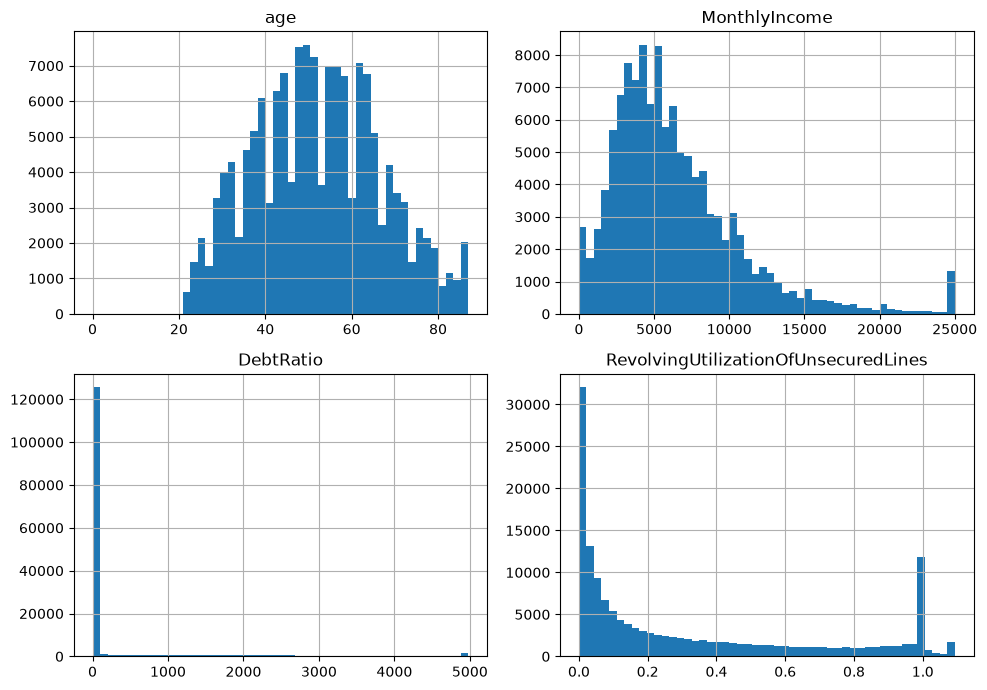

In [14]:
cols = ["age", "MonthlyIncome", "DebtRatio",
        "RevolvingUtilizationOfUnsecuredLines"]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, c in zip(axes.ravel(), cols):
    df[c].clip(upper=df[c].quantile(0.99)).hist(bins=50, ax=ax)
    ax.set_title(c)

plt.tight_layout()
plt.show()

In [15]:
past_due = ["NumberOfTime30-59DaysPastDueNotWorse",
            "NumberOfTime60-89DaysPastDueNotWorse",
            "NumberOfTimes90DaysLate"]

for c in past_due:
    print(c)
    print(df[c].value_counts().sort_index().tail(5))

NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
11      1
12      2
13      1
96      5
98    264
Name: count, dtype: int64
NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
8       2
9       1
11      1
96      5
98    264
Name: count, dtype: int64
NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
14      2
15      2
17      1
96      5
98    264
Name: count, dtype: int64


In [16]:
print(df.groupby(df["MonthlyIncome"].isna())["SeriousDlqin2yrs"].mean())

MonthlyIncome
False    0.069486
True     0.056137
Name: SeriousDlqin2yrs, dtype: float64


## Findings from exploration
- The data has 150,000 borrowers and 11 columns: 1 target (SeriousDlqin2yrs) and 10 features.
- Defaults are rare: 6.68% of borrowers. The classes are very imbalanced, so accuracy would be misleading and I will use AUC, precision and recall.
- Two columns have missing values: MonthlyIncome (29,731 rows, 19.8%) and NumberOfDependents (3,924 rows, 2.6%). All other columns are complete.
- Some values look wrong: age has a minimum of 0, RevolvingUtilizationOfUnsecuredLines has a maximum of 50,708 (normal range is about 0 to 1), DebtRatio has a maximum of 329,664, and the three past-due columns contain the codes 96 (5 rows) and 98 (264 rows), which are not real counts.
- Default rate when income is known: 6.95%. When income is missing: 5.61%. So missing income carries a small but real signal, and I will keep an "income was missing" flag when I fill in the values.
- Next: split train/test first, then clean using the training data only.